<a href="https://colab.research.google.com/github/Fa-224/Image-Processing-Project/blob/main/Planty_Dataset_Inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Planty — Dataset Inspection
**Purpose:** Explore the PlantVillage dataset before applying image processing techniques.
## Functions and Their Uses
| Function / Attribute | Purpose |
|---|---|
| `dataset_download()` | Downloads the dataset |
| `os.listdir()` | Lists files and folders |
| `os.path.join()` | Creates file and folder paths |
| `os.path.isdir()` | Checks whether an item is a folder |
| `os.path.isfile()` | Checks whether an item is a file |
| `len()` | Counts items |
| `Counter()` | Counts occurrences of values |
| `Image.open()` | Opens an image |
| `Image.verify()` | Checks image file integrity |
| `image.size` | Returns image dimensions |
| `image.mode` | Returns the color mode |
| `os.path.splitext()` | Extracts the file extension |
| `plt.imshow()` | Displays an image |
| `plt.barh()` | Creates a horizontal bar chart |
## Outcome
The dataset was inspected to understand its structure, class distribution, file extensions, image validity, dimensions, and color modes before selecting suitable image processing techniques.


In [ ]:
# Install the library used to access the dataset
!pip -q install kagglehub

In [ ]:
# Import the KaggleHub library
import kagglehub

# Download the PlantVillage dataset
dataset_path = kagglehub.dataset_download(
   "emmarex/plantdisease"
)

# Display the dataset location
print(dataset_path)

100%|██████████| 658M/658M [00:06<00:00, 100MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/emmarex/plantdisease/versions/1


In [ ]:
# Import libraries for file handling, image processing, and visualization
import os
print(os.listdir(dataset_path)) # Display the main folders in the dataset

['plantvillage', 'PlantVillage']


In [ ]:
# Set the dataset folder path
folder_path = os.path.join(dataset_path, "PlantVillage")
print(os.listdir(folder_path)[:20])

['Potato___Early_blight', 'Tomato_healthy', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Leaf_Mold', 'Potato___Late_blight', 'Tomato__Target_Spot', 'Potato___healthy', 'Tomato_Late_blight', 'Tomato_Bacterial_spot', 'Tomato__Tomato_mosaic_virus', 'Pepper__bell___Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Pepper__bell___healthy', 'Tomato_Early_blight']


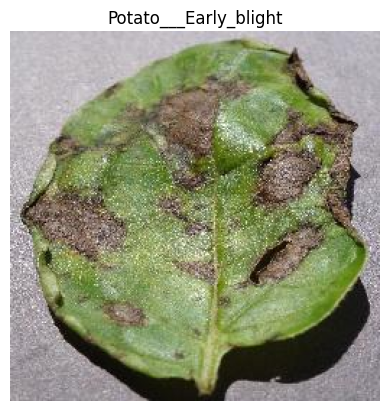

Image size: (256, 256)
Image mode: RGB


In [ ]:
# Import the libraries needed to display and process images
import matplotlib.pyplot as plt
from PIL import Image

# Specify the plant disease category we want to inspect
class_name = "Potato___Early_blight"

# Get the path of the selected category folder
class_path = os.path.join(folder_path, class_name)

# Select the first image from the category folder
image_name = os.listdir(class_path)[0]

# Get the complete path of the selected image
image_path = os.path.join(class_path, image_name)

# Open the image
image = Image.open(image_path)

# Display the image
plt.imshow(image)

plt.title(class_name)  # Add the category name as the image title
plt.axis("off")         # Hide the coordinate axes
plt.show()

# Print the image dimensions (width, height)
print("Image size:", image.size)

# Print the image color mode (e.g., RGB)
print("Image mode:", image.mode)


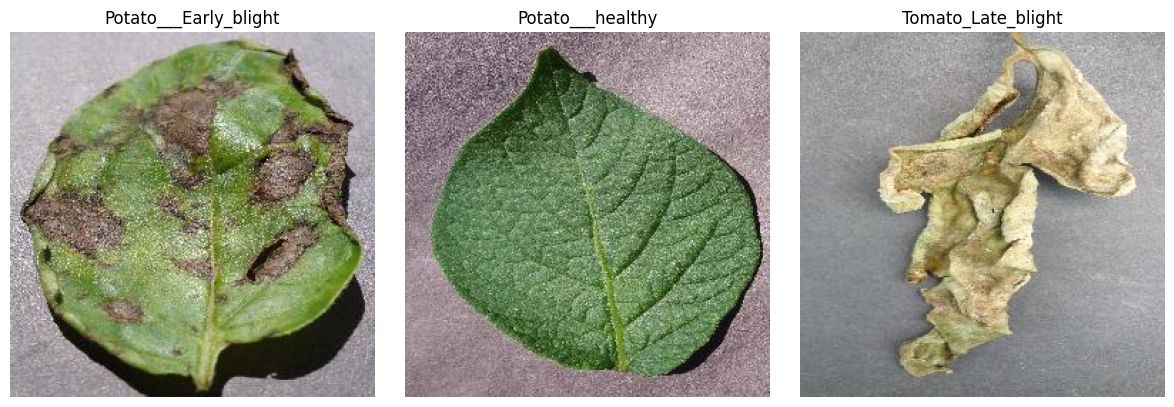

In [ ]:
# Select three categories
class_names = ["Potato___Early_blight", "Potato___healthy", "Tomato_Late_blight"]

# Create a figure
plt.figure(figsize=(12, 4))
for i, class_name in enumerate(class_names):

    # Get the image path
    class_path = os.path.join(folder_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    # Display the image
    image = Image.open(image_path)
    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

# Show all images
plt.tight_layout()
plt.show()


In [ ]:
# Count the categories and images in the dataset
class_names = [
   name for name in os.listdir(folder_path)
   if os.path.isdir(os.path.join(folder_path, name))
]
total_images = sum(
   len(os.listdir(os.path.join(folder_path, name)))
   for name in class_names
)
print("Number of classes:", len(class_names))
print("Total number of images:", total_images)

Number of classes: 15
Total number of images: 20639


In [ ]:
# Count images in each category
for name in sorted(class_names):
   class_path = os.path.join(folder_path, name)
   image_count = len(os.listdir(class_path))
   print(f"{name}: {image_count} images")

Pepper__bell___Bacterial_spot: 997 images
Pepper__bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3209 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato_healthy: 1591 images


In [ ]:
from collections import Counter
# Store the count of each file extension
extensions = Counter()
# Loop through all dataset classes
for class_name in class_names:
   class_path = os.path.join(folder_path, class_name)
   # Check each file in the class folder
   for file_name in os.listdir(class_path):
       file_path = os.path.join(class_path, file_name)
       # Count the extension of each file
       if os.path.isfile(file_path):
           extension = os.path.splitext(file_name)[1].lower()
           extensions[extension] += 1
# Display the results
print("File extensions:")
for extension, count in sorted(extensions.items()):
   print(f"{extension or 'No extension'}: {count}")

File extensions:
No extension: 1
.jpeg: 1
.jpg: 20636
.png: 1


In [ ]:
# Verify dataset image files
from PIL import Image
valid_images = 0
invalid_files = []
for class_name in class_names:
   class_path = os.path.join(folder_path, class_name)
   for file_name in os.listdir(class_path):
       file_path = os.path.join(class_path, file_name)
       if os.path.isfile(file_path):
           try:
               with Image.open(file_path) as image:
                   image.verify()
               valid_images += 1
           except Exception:
               invalid_files.append(file_path)
print("Valid images:", valid_images)
print("Invalid files:", len(invalid_files))

Valid images: 20638
Invalid files: 1


In [ ]:
# Identify the invalid file
print(invalid_files)

['/root/.cache/kagglehub/datasets/emmarex/plantdisease/versions/1/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c']


In [ ]:
# Inspect the invalid file
file_path = invalid_files[0]
print("File name:", os.path.basename(file_path))
print("File size:", os.path.getsize(file_path), "bytes")
print("File type:", Image.open if False else "Checking...")

File name: svn-r6Yb5c
File size: 0 bytes
File type: Checking...


In [ ]:
# Analyze image dimensions across the dataset
from collections import Counter
from PIL import Image
image_sizes = Counter()
for class_name in class_names:
   class_path = os.path.join(folder_path, class_name)
   for file_name in os.listdir(class_path):
       file_path = os.path.join(class_path, file_name)
       if os.path.isfile(file_path):
           try:
               with Image.open(file_path) as image:
                   image_sizes[image.size] += 1
           except Exception:
               continue
print("Image dimensions and counts:")
for size, count in image_sizes.most_common():
   print(f"{size}: {count}")

Image dimensions and counts:
(256, 256): 20638


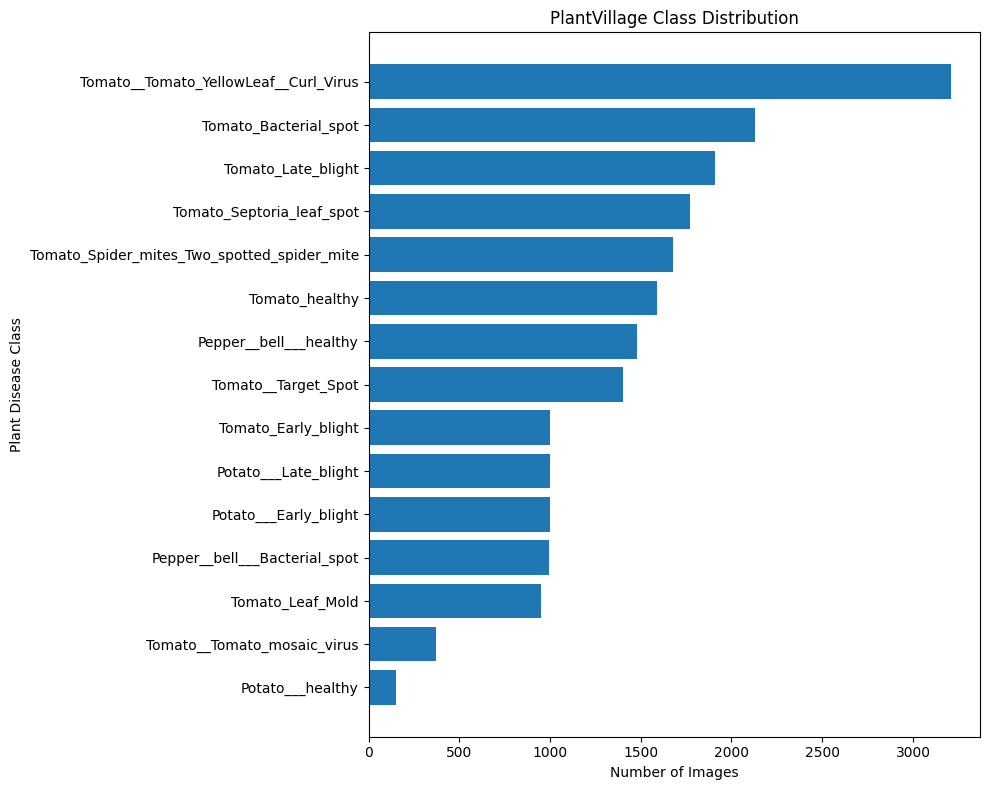

In [ ]:
# Visualize class distribution
import matplotlib.pyplot as plt
class_counts = {
   name: len(os.listdir(os.path.join(folder_path, name)))
   for name in class_names
}
sorted_counts = dict(sorted(class_counts.items(), key=lambda item: item[1]))
plt.figure(figsize=(10, 8))
plt.barh(list(sorted_counts.keys()), list(sorted_counts.values()))
plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("PlantVillage Class Distribution")
plt.tight_layout()
plt.show()

In [ ]:
# Perform complete dataset validation
from collections import Counter
from PIL import Image
import os
extension_counts = Counter()
dimension_counts = Counter()
mode_counts = Counter()
valid_images = 0
invalid_files = []
total_files = 0
for class_name in class_names:
   class_path = os.path.join(folder_path, class_name)
   for file_name in os.listdir(class_path):
       file_path = os.path.join(class_path, file_name)
       if not os.path.isfile(file_path):
           continue
       total_files += 1
       extension = os.path.splitext(file_name)[1].lower()
       extension_counts[extension or "No extension"] += 1
       try:
           with Image.open(file_path) as image:
               image.verify()
           with Image.open(file_path) as image:
               dimension_counts[image.size] += 1
               mode_counts[image.mode] += 1
           valid_images += 1
       except Exception:
           invalid_files.append(file_path)
print("=== Dataset Validation Report ===")
print("Total files:", total_files)
print("Valid images:", valid_images)
print("Invalid files:", len(invalid_files))
print("\n=== File Extensions ===")
for ext, count in sorted(extension_counts.items()):
   print(f"{ext}: {count}")
print("\n=== Image Dimensions ===")
for size, count in dimension_counts.most_common():
   print(f"{size}: {count}")
print("\n=== Image Color Modes ===")
for mode, count in mode_counts.most_common():
   print(f"{mode}: {count}")
print("\n=== Invalid Files ===")
for file_path in invalid_files:
   print(file_path)

=== Dataset Validation Report ===
Total files: 20639
Valid images: 20638
Invalid files: 1

=== File Extensions ===
.jpeg: 1
.jpg: 20636
.png: 1
No extension: 1

=== Image Dimensions ===
(256, 256): 20638

=== Image Color Modes ===
RGB: 20637
RGBA: 1

=== Invalid Files ===
/root/.cache/kagglehub/datasets/emmarex/plantdisease/versions/1/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c


# Dataset Inspection Summary
The PlantVillage dataset was inspected to understand its structure, class distribution, and image properties before selecting suitable image processing techniques.
## Dataset Statistics
- **Dataset:** PlantVillage
- **Dataset Source:** [PlantVillage Dataset on Kaggle](https://www.kaggle.com/datasets/emmarex/plantdisease)
- **Number of Classes:** 15
- **Total Number of Files:** 20,639
- **Valid Images:** 20,638
- **Invalid Files:** 1 (empty file, 0 bytes)
- **Most Common File Extension:** .jpg
- **Image Dimensions:** 256 × 256 pixels (all valid images)
- **Color Mode:** 20,637 RGB images and 1 RGBA image
## Class Distribution
The dataset contains 15 classes with different numbers of files.
- **Largest Class:** Tomato__Tomato_YellowLeaf__Curl_Virus (3,209 files)
- **Smallest Class:** Potato___healthy (152 files)
The class distribution plot illustrates the differences in the number of files across categories.
## File Validation
The file extensions were inspected, and the image files were checked for validity.
- 20,638 files passed image validation.
- One empty file with a size of 0 bytes was identified.
- The empty file was not counted as a valid image.
## Observations
- The dataset contains images of healthy and diseased plant leaves.
- The number of files varies across the 15 classes.
- Most files use the JPG extension.
- All 20,638 valid images have the same dimensions of 256 × 256 pixels.
- The inspected sample image had an RGB color mode.
- One empty file was identified during validation.
## Conclusion
The initial dataset inspection provided an overview of the dataset structure, class distribution, file extensions, and image properties. A total of 20,638 valid images were identified, all with dimensions of 256 × 256 pixels, along with one empty file.
These findings provide a basis for selecting appropriate preprocessing techniques before proceeding with feature extraction and plant disease classification.